# Sanity checks

Run after `prepare_games.py`. Anything odd here is cheaper to fix now than after training.

In [1]:
import pandas as pd

df = pd.read_parquet("games/part-000.parquet")  # one shard is plenty for sanity checks
df["n_moves"] = df.moves.map(len)
df["base"] = df.TimeControl.str.split("+").str[0].astype(int)
print(f"{len(df):,} games")
df.describe()

650,611 games


,WhiteElo,BlackElo,n_moves,base
count,650611.000000,650611.000000,650611.000000,650611.000000
mean,1619.007458,1618.868007,68.092908,227.342321
std,361.364847,361.517061,31.978762,59.290630
min,400.000000,400.000000,1.000000,0.000000
25%,1371.000000,1370.000000,45.000000,180.000000
50%,1638.000000,1639.000000,64.000000,180.000000
75%,1878.000000,1878.000000,87.000000,300.000000
max,2995.000000,2990.000000,307.000000,420.000000


Ratings, and the gap between the two players. Matchmaking should keep the gap narrow.

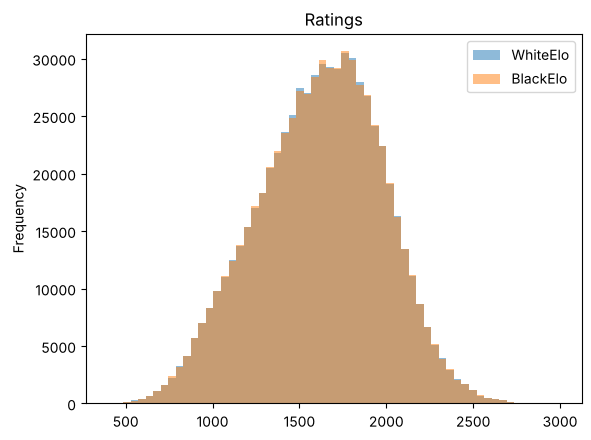

In [2]:
df[["WhiteElo", "BlackElo"]].plot.hist(bins=60, alpha=0.5, title="Ratings");

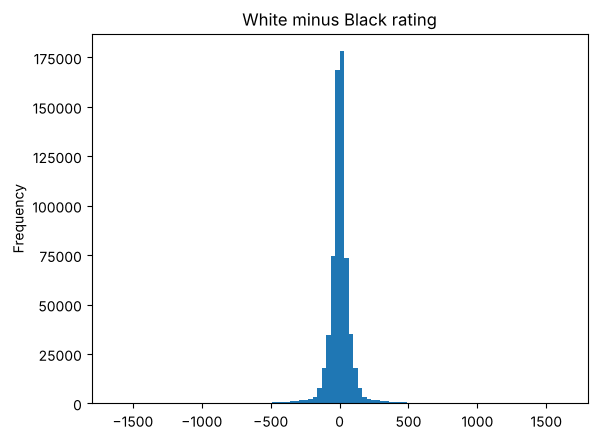

In [3]:
(df.WhiteElo - df.BlackElo).plot.hist(bins=100, title="White minus Black rating");

Game length, time controls, and the move vocabulary (the number of tokens the model will see).

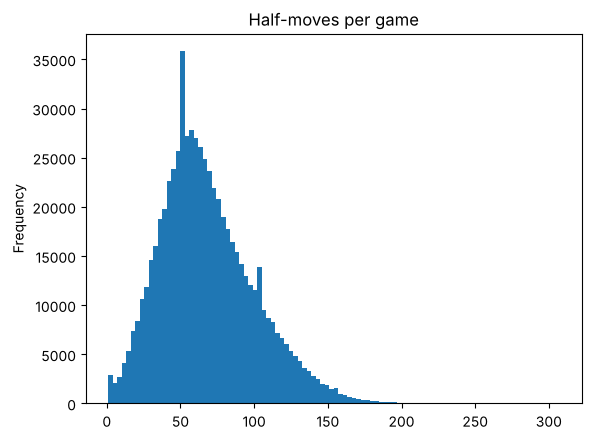

In [4]:
df.n_moves.plot.hist(bins=100, title="Half-moves per game");

In [5]:
print(df.moves.explode().nunique(), "distinct SAN moves")
df.TimeControl.value_counts().head(10)

10073 distinct SAN moves


TimeControl
180+0    267460
300+0    185099
180+2    122823
300+3     68911
240+0       857
300+2       664
180+1       627
420+0       592
180+3       557
300+4       513
Name: count, dtype: int64

Clocks: the first clock should equal the base time, none should be negative, and White's clock should mostly fall.

first clock == base time: 0.9903890343077507
negative clocks: 0


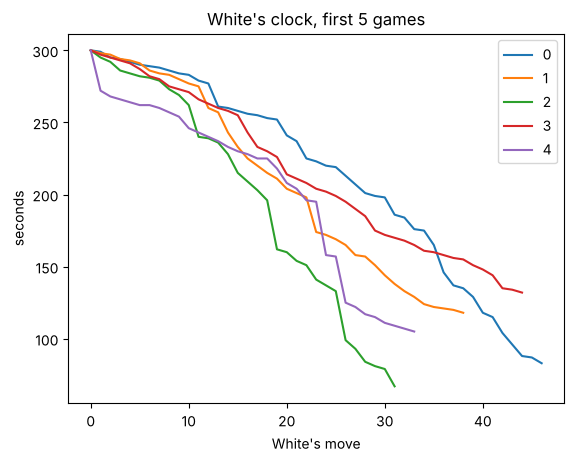

In [6]:
print("first clock == base time:", (df.clocks.map(lambda c: c[0]) == df.base).mean())
print("negative clocks:", (df.clocks.map(min) < 0).sum())
pd.DataFrame([list(c[0::2]) for c in df.clocks.head(5)]).T.plot(
    title="White's clock, first 5 games", xlabel="White's move", ylabel="seconds");